# Exploratory Data Analysis and Subset Selection for CICIoT2023

This notebook profiles the complete CICIoT2023 CSV collection, reports the



Reference : Full_CICIoT2023_Dataset : https://www.kaggle.com/datasets/madhavmalhotra/unb-cic-iot-dataset   

## 1. Environment Setup and Configuration


In [29]:
from collections import Counter
from pathlib import Path
import random
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print(f"Global random seed: {SEED}")


Global random seed: 42


In [31]:
# Dataset location

CSV_DIR = Path("data") / "Full_CICIoT2023_Dataset"

if not CSV_DIR.is_dir():
    raise FileNotFoundError(
        "Dataset folder not found. Download the dataset using the "
        "repository link in README.md and place the CSV files in "
        "'data/Full_CICIoT2023_Dataset/'."
    )

# Dataset constants
LABEL_COL = "label"
EXPECTED_FILES = 169
EXPECTED_COLUMNS = 47
EXPECTED_ORIGINAL_CLASSES = 34
EXPECTED_CLASS_FAMILIES = 8
EXPECTED_SUBSET_ROWS = 591_229
CHUNK_SIZE = 500_000


## 2. Reusable Class-Aggregation and Summary Functions


In [34]:
def group_ciciot2023_classes(df, label_col=LABEL_COL):
    '''Group the 34 original CICIoT2023 labels into eight class families.'''
    grouped_df = df.copy()

    # Preserve the original mapping exactly
    grouped_df[label_col] = grouped_df[label_col].replace(
        "DDoS.*", "DDoS", regex=True
    )
    grouped_df[label_col] = grouped_df[label_col].replace(
        "DoS.*", "DoS", regex=True
    )
    grouped_df[label_col] = grouped_df[label_col].replace(
        "Mirai.*", "Mirai", regex=True
    )
    grouped_df[label_col] = grouped_df[label_col].replace(
        [
            "Recon-PingSweep",
            "Recon-OSScan",
            "Recon-PortScan",
            "VulnerabilityScan",
            "Recon-HostDiscovery",
        ],
        "Recon",
    )
    grouped_df[label_col] = grouped_df[label_col].replace(
        ["DNS_Spoofing", "MITM-ArpSpoofing"],
        "Spoofing",
    )
    grouped_df[label_col] = grouped_df[label_col].replace(
        "BenignTraffic", "Benign"
    )
    grouped_df[label_col] = grouped_df[label_col].replace(
        [
            "BrowserHijacking",
            "Backdoor_Malware",
            "XSS",
            "Uploading_Attack",
            "SqlInjection",
            "CommandInjection",
        ],
        "Web",
    )
    grouped_df[label_col] = grouped_df[label_col].replace(
        "DictionaryBruteForce", "BruteForce", regex=True
    )

    return grouped_df


def class_distribution_table(df, label_col=LABEL_COL):
    '''Return class counts and percentages in descending order.'''
    distribution = (
        df[label_col]
        .value_counts()
        .rename_axis("Class")
        .reset_index(name="Count")
    )
    distribution["Percentage (%)"] = (
        distribution["Count"] / len(df) * 100
    )
    return distribution


## 3. Full-Dataset Profiling and Highest-File Selection


In [37]:
if not CSV_DIR.is_dir():
    raise FileNotFoundError(f"Dataset directory not found: {CSV_DIR}")

# Match only the 169 original CICIoT2023 CSV files
source_file_pattern = re.compile(
    r"^part-\d{5}-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000\.csv$"
)

csv_files = sorted(
    [
        file_path
        for file_path in CSV_DIR.iterdir()
        if file_path.is_file()
        and source_file_pattern.fullmatch(file_path.name)
    ],
    key=lambda file_path: int(file_path.name.split("-")[1]),
)

if len(csv_files) != EXPECTED_FILES:
    raise ValueError(
        f"Expected {EXPECTED_FILES} source CSV files, but found "
        f"{len(csv_files)}."
    )

print(f"Number of CICIoT2023 source files: {len(csv_files)}\n")

class_counts = Counter()
file_information = []
total_instances = 0
expected_header = None

for file_number, file_path in enumerate(csv_files, start=1):
    file_header = pd.read_csv(file_path, nrows=0).columns.tolist()

    if expected_header is None:
        expected_header = file_header
    elif file_header != expected_header:
        raise ValueError(f"Column mismatch detected in {file_path.name}.")

    if len(file_header) != EXPECTED_COLUMNS:
        raise ValueError(
            f"Expected {EXPECTED_COLUMNS} columns in {file_path.name}, "
            f"but found {len(file_header)}."
        )

    if LABEL_COL not in file_header:
        raise KeyError(f"Column '{LABEL_COL}' not found in {file_path.name}.")

    file_rows = 0

    for chunk in pd.read_csv(
        file_path,
        usecols=[LABEL_COL],
        chunksize=CHUNK_SIZE,
    ):
        counts = chunk[LABEL_COL].value_counts()
        class_counts.update(
            {
                str(class_name): int(count)
                for class_name, count in counts.items()
            }
        )

        chunk_rows = len(chunk)
        file_rows += chunk_rows
        total_instances += chunk_rows

    file_information.append(
        {
            "Original File Number": file_number,
            "File Name": file_path.name,
            "Instances": file_rows,
            "Columns": len(file_header),
            "File Path": file_path,
        }
    )

    print(
        f"[{file_number:03d}/{len(csv_files)}] "
        f"Shape: ({file_rows:,}, {len(file_header)}) - {file_path.name}"
    )


Number of CICIoT2023 source files: 169

[001/169] Shape: (238,687, 47) - part-00000-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[002/169] Shape: (218,805, 47) - part-00001-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[003/169] Shape: (275,258, 47) - part-00002-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[004/169] Shape: (231,023, 47) - part-00003-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[005/169] Shape: (227,491, 47) - part-00004-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[006/169] Shape: (240,046, 47) - part-00005-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[007/169] Shape: (233,793, 47) - part-00006-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[008/169] Shape: (227,910, 47) - part-00007-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[009/169] Shape: (246,327, 47) - part-00008-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[010/169] Shape: (227,616, 47) - part-00009-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[011/169] Shape: (251,392, 47) - part-00010-363d1ba3-8ab5-4f

### 3.1 Original 34-Class Distribution


In [39]:
class_distribution = pd.DataFrame(
    class_counts.items(),
    columns=["Class", "Count"],
).sort_values("Count", ascending=False, ignore_index=True)

class_distribution["Percentage (%)"] = (
    class_distribution["Count"] / total_instances * 100
)

if len(class_distribution) != EXPECTED_ORIGINAL_CLASSES:
    raise ValueError(
        f"Expected {EXPECTED_ORIGINAL_CLASSES} original classes, but found "
        f"{len(class_distribution)}."
    )

if int(class_distribution["Count"].sum()) != total_instances:
    raise ValueError("Class counts do not equal the total number of instances.")

print("Full CICIoT2023 class distribution:")
display(
    class_distribution.style.format(
        {"Count": "{:,}", "Percentage (%)": "{:.6f}"}
    )
)

print("Full dataset summary:")
print(f"Shape: ({total_instances:,}, {EXPECTED_COLUMNS})")
print(f"Number of files: {len(csv_files)}")
print(f"Total instances: {total_instances:,}")
print(f"Number of original classes: {len(class_distribution)}")
print(f"Sum of class counts: {class_distribution['Count'].sum():,}")


Full CICIoT2023 class distribution:


,Class,Count,Percentage (%)
0,DDoS-ICMP_Flood,"7,200,504",15.423071
1,DDoS-UDP_Flood,"5,412,287",11.592811
2,DDoS-TCP_Flood,"4,497,667",9.633747
3,DDoS-PSHACK_Flood,"4,094,755",8.770733
4,DDoS-SYN_Flood,"4,059,190",8.694554
5,DDoS-RSTFINFlood,"4,045,285",8.664771
6,DDoS-SynonymousIP_Flood,"3,598,138",7.707007
7,DoS-UDP_Flood,"3,318,595",7.108242
8,DoS-TCP_Flood,"2,671,445",5.722083
9,DoS-SYN_Flood,"2,028,834",4.345647


Full dataset summary:
Shape: (46,686,579, 47)
Number of files: 169
Total instances: 46,686,579
Number of original classes: 34
Sum of class counts: 46,686,579


### 3.2 Aggregated Eight-Class Distribution


In [42]:
full_count_table = pd.DataFrame(
    {
        LABEL_COL: list(class_counts.keys()),
        "Count": list(class_counts.values()),
    }
)

full_count_table = group_ciciot2023_classes(full_count_table)

family_distribution = (
    full_count_table.groupby(LABEL_COL, as_index=False)["Count"]
    .sum()
    .rename(columns={LABEL_COL: "Class Family"})
    .sort_values("Count", ascending=False, ignore_index=True)
)

family_distribution["Percentage (%)"] = (
    family_distribution["Count"] / total_instances * 100
)

if len(family_distribution) != EXPECTED_CLASS_FAMILIES:
    raise ValueError(
        f"Expected {EXPECTED_CLASS_FAMILIES} class families, but obtained "
        f"{len(family_distribution)}."
    )

print("Eight-class distribution of the full CICIoT2023 dataset:")
display(
    family_distribution.style.format(
        {"Count": "{:,}", "Percentage (%)": "{:.6f}"}
    )
)

print(f"Original classes: {len(class_distribution)}")
print(f"Aggregated class families: {len(family_distribution)}")
print(f"Total instances: {total_instances:,}")
print(f"Sum of family counts: {family_distribution['Count'].sum():,}")


Eight-class distribution of the full CICIoT2023 dataset:


,Class Family,Count,Percentage (%)
0,DDoS,"33,984,560",72.792997
1,DoS,"8,090,738",17.329901
2,Mirai,"2,634,124",5.642144
3,Benign,"1,098,195",2.352271
4,Spoofing,"486,504",1.042064
5,Recon,"354,565",0.759458
6,Web,"24,829",0.053182
7,BruteForce,"13,064",0.027982


Original classes: 34
Aggregated class families: 8
Total instances: 46,686,579
Sum of family counts: 46,686,579


### 3.3 Select the File with the Highest Number of Instances


In [45]:
file_size_distribution = (
    pd.DataFrame(file_information)
    .sort_values("Instances", ascending=False, ignore_index=True)
)
file_size_distribution.insert(
    0,
    "Size Rank",
    range(1, len(file_size_distribution) + 1),
)

largest_file = file_size_distribution.iloc[[0]].copy()
selected_csv_file = largest_file.iloc[0]["File Path"]
selected_file_rows = int(largest_file.iloc[0]["Instances"])
selected_file_columns = int(largest_file.iloc[0]["Columns"])

print("Selected source file:")
display(
    largest_file[
        [
            "Size Rank",
            "Original File Number",
            "File Name",
            "Instances",
            "Columns",
        ]
    ].style.format({"Instances": "{:,}"})
)


Selected source file:


,Size Rank,Original File Number,File Name,Instances,Columns
0,1,114,part-00113-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv,"451,498",47


## 4. Experimental Subset Construction
 ##### Create a dataset subset by combining the  CSV with the highest number of instances from the 169 CSV files with other CSV files used in previous studies.

### 4.1 First CSV File: Highest Number of Instances


In [49]:
df_first_csv = pd.read_csv(selected_csv_file, low_memory=False)

print(f"File: {selected_csv_file.name}")
print(f"Shape: {df_first_csv.shape}")
df_first_csv.info()

print("Original class distribution:")
display(
    class_distribution_table(df_first_csv).style.format(
        {"Count": "{:,}", "Percentage (%)": "{:.6f}"}
    )
)


File: part-00113-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
Shape: (451498, 47)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 451498 entries, 0 to 451497
Data columns (total 47 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   flow_duration    451498 non-null  float64
 1   Header_Length    451498 non-null  float64
 2   Protocol Type    451498 non-null  float64
 3   Duration         451498 non-null  float64
 4   Rate             451498 non-null  float64
 5   Srate            451498 non-null  float64
 6   Drate            451498 non-null  float64
 7   fin_flag_number  451498 non-null  float64
 8   syn_flag_number  451498 non-null  float64
 9   rst_flag_number  451498 non-null  float64
 10  psh_flag_number  451498 non-null  float64
 11  ack_flag_number  451498 non-null  float64
 12  ece_flag_number  451498 non-null  float64
 13  cwr_flag_number  451498 non-null  float64
 14  ack_count        451498 non-null  float64
 15  sy

,Class,Count,Percentage (%)
0,DDoS-ICMP_Flood,"69,891",15.479803
1,DDoS-UDP_Flood,"52,210",11.563728
2,DDoS-TCP_Flood,"43,822",9.705912
3,DDoS-PSHACK_Flood,"39,371",8.720083
4,DDoS-SYN_Flood,"39,269",8.697491
5,DDoS-RSTFINFlood,"39,017",8.641677
6,DDoS-SynonymousIP_Flood,"34,611",7.665815
7,DoS-UDP_Flood,"32,116",7.113210
8,DoS-TCP_Flood,"25,794",5.712982
9,DoS-SYN_Flood,"19,397",4.296143


In [51]:
#### Aggregate the Original Labels into Eight Class Families


In [53]:
df_CICIoT2023_S1 = group_ciciot2023_classes(df_first_csv)

first_file_distribution = class_distribution_table(df_CICIoT2023_S1)

print("First CSV file: eight-class distribution")
display(
    first_file_distribution.style.format(
        {"Count": "{:,}", "Percentage (%)": "{:.6f}"}
    )
)


First CSV file: eight-class distribution


,Class,Count,Percentage (%)
0,DDoS,"328,601",72.780167
1,DoS,"78,047",17.286234
2,Mirai,"25,726",5.697921
3,Benign,"10,507",2.327142
4,Spoofing,"4,731",1.047845
5,Recon,"3,515",0.778520
6,Web,238,0.052713
7,BruteForce,133,0.029457


### 4.2 Second CSV File: File Used in Previous Studies from the 169 CSV Files

The second source file corresponds to the file used in the
[reference study](https://www.sciencedirect.com/science/article/pii/S2772671124002535).



In [56]:
#### Check the distributions' alignment before combining  with the first CSV 

In [58]:
second_csv_path = CSV_DIR / (
    "part-00016-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv"
)
df_second_csv = pd.read_csv(second_csv_path, low_memory=False)

print(f"File: {second_csv_path.name}")
print(f"Shape: {df_second_csv.shape}")
df_second_csv.info()

print("Original class distribution:")
display(
    class_distribution_table(df_second_csv).style.format(
        {"Count": "{:,}", "Percentage (%)": "{:.6f}"}
    )
)


File: part-00016-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
Shape: (232885, 47)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 232885 entries, 0 to 232884
Data columns (total 47 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   flow_duration    232885 non-null  float64
 1   Header_Length    232885 non-null  float64
 2   Protocol Type    232885 non-null  float64
 3   Duration         232885 non-null  float64
 4   Rate             232885 non-null  float64
 5   Srate            232885 non-null  float64
 6   Drate            232885 non-null  float64
 7   fin_flag_number  232885 non-null  float64
 8   syn_flag_number  232885 non-null  float64
 9   rst_flag_number  232885 non-null  float64
 10  psh_flag_number  232885 non-null  float64
 11  ack_flag_number  232885 non-null  float64
 12  ece_flag_number  232885 non-null  float64
 13  cwr_flag_number  232885 non-null  float64
 14  ack_count        232885 non-null  float64
 15  sy

,Class,Count,Percentage (%)
0,DDoS-ICMP_Flood,"35,898",15.414475
1,DDoS-UDP_Flood,"26,895",11.548618
2,DDoS-TCP_Flood,"22,395",9.616334
3,DDoS-PSHACK_Flood,"20,561",8.828821
4,DDoS-SYN_Flood,"20,216",8.680679
5,DDoS-RSTFINFlood,"20,015",8.594371
6,DDoS-SynonymousIP_Flood,"17,966",7.714537
7,DoS-UDP_Flood,"16,727",7.182515
8,DoS-TCP_Flood,"13,247",5.688215
9,DoS-SYN_Flood,"10,177",4.369968


In [60]:
#### Aggregate the Original Labels into Eight Class Families

In [62]:
df_CICIoT2023_S2 = group_ciciot2023_classes(df_second_csv)

second_file_distribution = class_distribution_table(df_CICIoT2023_S2)

print("Second CSV file: eight-class distribution")
display(
    second_file_distribution.style.format(
        {"Count": "{:,}", "Percentage (%)": "{:.6f}"}
    )
)


Second CSV file: eight-class distribution


,Class,Count,Percentage (%)
0,DDoS,"169,276",72.686519
1,DoS,"40,492",17.387122
2,Mirai,"13,322",5.720420
3,Benign,"5,400",2.318741
4,Spoofing,"2,473",1.061898
5,Recon,"1,742",0.748009
6,Web,125,0.053675
7,BruteForce,55,0.023617


In [64]:
### Create samples from the 2nd CSV Stratified Extraction to combine with the First CSV

In [66]:
df_second_csv_60, df_second_csv_40 = train_test_split(
    df_CICIoT2023_S2,
    train_size=0.60,
    stratify=df_CICIoT2023_S2[LABEL_COL],
    random_state=SEED,
)

df_second_csv_60 = df_second_csv_60.reset_index(drop=True)

print(f"Retained 60% subset shape: {df_second_csv_60.shape}")
display(
    class_distribution_table(df_second_csv_60).style.format(
        {"Count": "{:,}", "Percentage (%)": "{:.6f}"}
    )
)


Retained 60% subset shape: (139731, 47)


,Class,Count,Percentage (%)
0,DDoS,"101,566",72.686805
1,DoS,"24,295",17.386979
2,Mirai,"7,993",5.720277
3,Benign,"3,240",2.318741
4,Spoofing,"1,484",1.062041
5,Recon,"1,045",0.747866
6,Web,75,0.053675
7,BruteForce,33,0.023617


### 4.4 Final Subset for this study


In [69]:
df_CICIoT2023_concat = pd.concat(
    [df_CICIoT2023_S1, df_second_csv_60],
    ignore_index=True,
)

if len(df_CICIoT2023_concat) != EXPECTED_SUBSET_ROWS:
    raise ValueError(
        f"Expected {EXPECTED_SUBSET_ROWS:,} combined instances, but obtained "
        f"{len(df_CICIoT2023_concat):,}."
    )

combined_distribution = class_distribution_table(df_CICIoT2023_concat)

print("Constructed subset summary:")
print(f"Shape: {df_CICIoT2023_concat.shape}")
print(f"Number of class families: {df_CICIoT2023_concat[LABEL_COL].nunique()}")
display(
    combined_distribution.style.format(
        {"Count": "{:,}", "Percentage (%)": "{:.6f}"}
    )
)


Constructed subset summary:
Shape: (591229, 47)
Number of class families: 8


,Class,Count,Percentage (%)
0,DDoS,"430,167",72.758102
1,DoS,"102,342",17.310044
2,Mirai,"33,719",5.703205
3,Benign,"13,747",2.325157
4,Spoofing,"6,215",1.051200
5,Recon,"4,560",0.771275
6,Web,313,0.052941
7,BruteForce,166,0.028077


### 4.5 Save Final Eight-Class Subset for Anomaly Score Generators Models and DL Classifier


In [120]:
df_CICIoT2023_concat.to_csv(
    "df_CICIoT2023_subset.csv",
    index=False,
)

print("Constructed subset saved .")

Constructed subset saved .


## 5. Exploratory Analysis of the Constructed Subset

In [73]:
print("Constructed subset statistics:")
print(f"Instances: {len(df_CICIoT2023_concat):,}")
print(f"Columns: {df_CICIoT2023_concat.shape[1]}")
print(f"Class families: {df_CICIoT2023_concat[LABEL_COL].nunique()}")

display(df_CICIoT2023_concat.head())


Constructed subset statistics:
Instances: 591,229
Columns: 47
Class families: 8


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,ack_count,syn_count,fin_count,urg_count,rst_count,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IPv,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,0.000000,0.0,1.0,102.2,204.980158,204.980158,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,441.0,42.0,42.0,42.0,0.0,42.0,8.315011e+07,9.5,9.165151,0.0,0.0,0.0,141.55,DDoS
1,0.000000,54.0,6.0,64.0,0.000000,0.000000,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,567.0,54.0,54.0,54.0,0.0,54.0,8.334862e+07,9.5,10.392305,0.0,0.0,0.0,141.55,DDoS
2,0.000000,54.0,6.0,64.0,0.000000,0.000000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,567.0,54.0,54.0,54.0,0.0,54.0,8.308927e+07,9.5,10.392305,0.0,0.0,0.0,141.55,DDoS
3,3.394034,210.6,6.0,64.0,1.144677,1.144677,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,3.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,567.0,54.0,54.0,54.0,0.0,54.0,8.336215e+07,9.5,10.392305,0.0,0.0,0.0,141.55,DDoS
4,0.000000,54.0,6.0,64.0,0.992022,0.992022,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,567.0,54.0,54.0,54.0,0.0,54.0,8.334381e+07,9.5,10.392305,0.0,0.0,0.0,141.55,DDoS


### 5.1 Class-Distribution Visualization


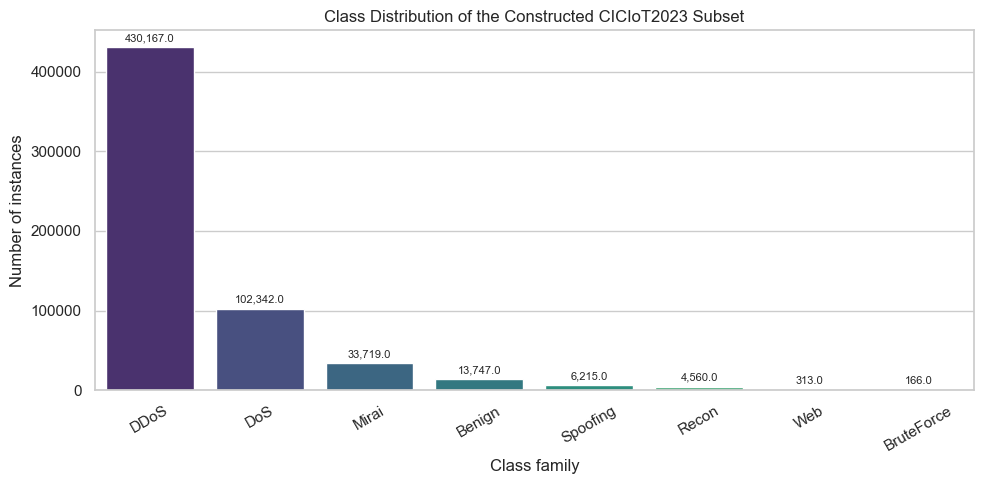

In [75]:
subset_class_counts = df_CICIoT2023_concat[LABEL_COL].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    x=subset_class_counts.index,
    y=subset_class_counts.values,
    hue=subset_class_counts.index,
    palette="viridis",
    legend=False,
    ax=ax,
)

ax.set_title("Class Distribution of the Constructed CICIoT2023 Subset")
ax.set_xlabel("Class family")
ax.set_ylabel("Number of instances")
ax.tick_params(axis="x", rotation=30)

for container in ax.containers:
    ax.bar_label(container, fmt="{:,}", padding=3, fontsize=8)

plt.tight_layout()
plt.show()


## 6. Subset Representativeness Analysis

### 6.1 Class-Distribution Similarity
 Descriptive similarity is
assessed using the maximum absolute percentage-point difference, total
variation distance, and Jensen--Shannon divergence (base 2).

In [79]:
from scipy.spatial.distance import jensenshannon
from scipy.stats import chi2_contingency, ks_2samp

CLASS_ORDER = [
    "DDoS",
    "DoS",
    "Mirai",
    "Benign",
    "Spoofing",
    "Recon",
    "Web",
    "BruteForce",
]

full_family_counts = (
    family_distribution
    .set_index("Class Family")["Count"]
    .reindex(CLASS_ORDER, fill_value=0)
    .astype("int64")
)

subset_family_counts = (
    combined_distribution
    .set_index("Class")["Count"]
    .reindex(CLASS_ORDER, fill_value=0)
    .astype("int64")
)

if (full_family_counts <= 0).any():
    raise ValueError("Every class must occur in the complete dataset.")

if (subset_family_counts <= 0).any():
    raise ValueError("Every class must occur in the constructed subset.")

full_class_proportions = full_family_counts / full_family_counts.sum()
subset_class_proportions = subset_family_counts / subset_family_counts.sum()

class_representativeness = pd.DataFrame(
    {
        "Class": CLASS_ORDER,
        "Full count": full_family_counts.to_numpy(),
        "Subset count": subset_family_counts.to_numpy(),
        "Full proportion (%)": full_class_proportions.to_numpy() * 100,
        "Subset proportion (%)": subset_class_proportions.to_numpy() * 100,
    }
)

class_representativeness["Difference (percentage points)"] = (
    class_representativeness["Subset proportion (%)"]
    - class_representativeness["Full proportion (%)"]
)
class_representativeness["Absolute difference (percentage points)"] = (
    class_representativeness["Difference (percentage points)"].abs()
)

p_full = full_class_proportions.to_numpy(dtype=float)
p_subset = subset_class_proportions.to_numpy(dtype=float)

maximum_absolute_difference_pp = float(
    np.max(np.abs(p_full - p_subset)) * 100
)
total_variation_distance = float(
    0.5 * np.sum(np.abs(p_full - p_subset))
)
js_distance = float(jensenshannon(p_full, p_subset, base=2))
js_divergence = js_distance**2

# Construct the independent, non-overlapping class reference by removing
# every selected subset record from the complete-dataset class counts.
complement_family_counts = (
    full_family_counts - subset_family_counts
).astype("int64")

if (complement_family_counts < 0).any():
    invalid_classes = complement_family_counts[
        complement_family_counts < 0
    ].index.tolist()
    raise ValueError(
        "Subset counts exceed complete-dataset counts for classes: "
        f"{invalid_classes}"
    )

if complement_family_counts.sum() == 0:
    raise ValueError(
        "The non-overlapping complement contains no observations."
    )

if (
    subset_family_counts.sum() + complement_family_counts.sum()
    != full_family_counts.sum()
):
    raise ValueError(
        "Subset and complement counts do not reconstruct the complete dataset."
    )

# The 2 x 8 contingency table compares two disjoint groups and therefore
# avoids reusing subset observations in the chi-square reference group.
class_homogeneity_observed = np.vstack(
    [
        subset_family_counts.to_numpy(dtype="int64"),
        complement_family_counts.to_numpy(dtype="int64"),
    ]
)

(
    chi_square_statistic,
    chi_square_p_value,
    chi_square_degrees_of_freedom,
    chi_square_expected_counts,
) = chi2_contingency(
    class_homogeneity_observed,
    correction=False,
)

chi_square_comparison_counts = pd.DataFrame(
    {
        "Class": CLASS_ORDER,
        "Subset observed count": class_homogeneity_observed[0],
        "Complement observed count": class_homogeneity_observed[1],
        "Subset expected count": chi_square_expected_counts[0],
        "Complement expected count": chi_square_expected_counts[1],
    }
)

class_similarity_metrics = pd.DataFrame(
    {
        "Metric": [
            "Maximum absolute difference (percentage points)",
            "Total variation distance",
            "Jensen-Shannon divergence (base 2)",
            "Supplementary chi-square homogeneity statistic",
            "Chi-square degrees of freedom",
            "Supplementary chi-square homogeneity p-value",
        ],
        "Value": [
            maximum_absolute_difference_pp,
            total_variation_distance,
            js_divergence,
            chi_square_statistic,
            chi_square_degrees_of_freedom,
            chi_square_p_value,
        ],
    }
)

print("Class-distribution comparison:")
display(
    class_representativeness.style.format(
        {
            "Full count": "{:,}",
            "Subset count": "{:,}",
            "Full proportion (%)": "{:.6f}",
            "Subset proportion (%)": "{:.6f}",
            "Difference (percentage points)": "{:+.6f}",
            "Absolute difference (percentage points)": "{:.6f}",
        }
    )
)

print("Class-distribution similarity metrics:")
display(class_similarity_metrics.style.format({"Value": "{:.10g}"}))

print(
    f"Maximum absolute difference: "
    f"{maximum_absolute_difference_pp:.6f} percentage points"
)
print(f"Total variation distance: {total_variation_distance:.8f}")
print(f"Jensen-Shannon divergence (base 2): {js_divergence:.8e}")
print(
    "Supplementary chi-square homogeneity test "
    "(subset vs non-overlapping complement): "
    f"chi2({chi_square_degrees_of_freedom}) = "
    f"{chi_square_statistic:.4f}, p = {chi_square_p_value:.4f}"
)

print("Observed and expected counts for the homogeneity test:")
display(
    chi_square_comparison_counts.style.format(
        {
            "Subset observed count": "{:,}",
            "Complement observed count": "{:,}",
            "Subset expected count": "{:,.2f}",
            "Complement expected count": "{:,.2f}",
        }
    )
)

class_representativeness.to_csv(
    "CICIoT2023_class_distribution_comparison.csv",
    index=False,
)
class_similarity_metrics.to_csv(
    "CICIoT2023_class_similarity_metrics.csv",
    index=False,
)
chi_square_comparison_counts.to_csv(
    "CICIoT2023_chi_square_homogeneity_counts.csv",
    index=False,
)


Class-distribution comparison:


,Class,Full count,Subset count,Full proportion (%),Subset proportion (%),Difference (percentage points),Absolute difference (percentage points)
0,DDoS,"33,984,560","430,167",72.792997,72.758102,-0.034895,0.034895
1,DoS,"8,090,738","102,342",17.329901,17.310044,-0.019857,0.019857
2,Mirai,"2,634,124","33,719",5.642144,5.703205,+0.061061,0.061061
3,Benign,"1,098,195","13,747",2.352271,2.325157,-0.027115,0.027115
4,Spoofing,"486,504","6,215",1.042064,1.051200,+0.009136,0.009136
5,Recon,"354,565","4,560",0.759458,0.771275,+0.011817,0.011817
6,Web,"24,829",313,0.053182,0.052941,-0.000242,0.000242
7,BruteForce,"13,064",166,0.027982,0.028077,+0.000095,0.000095


Class-distribution similarity metrics:


,Metric,Value
0,Maximum absolute difference (percentage points),0.06106071438
1,Total variation distance,0.000821083366
2,Jensen-Shannon divergence (base 2),2.298825946e-06
3,Supplementary chi-square homogeneity statistic,7.654181748
4,Chi-square degrees of freedom,7
5,Supplementary chi-square homogeneity p-value,0.364072741


Maximum absolute difference: 0.061061 percentage points
Total variation distance: 0.00082108
Jensen-Shannon divergence (base 2): 2.29882595e-06
Supplementary chi-square homogeneity test (subset vs non-overlapping complement): chi2(7) = 7.6542, p = 0.3641
Observed and expected counts for the homogeneity test:


,Class,Subset observed count,Complement observed count,Subset expected count,Complement expected count
0,DDoS,"430,167","33,554,393","430,373.31","33,554,186.69"
1,DoS,"102,342","7,988,396","102,459.40","7,988,278.60"
2,Mirai,"33,719","2,600,405","33,357.99","2,600,766.01"
3,Benign,"13,747","1,084,448","13,907.31","1,084,287.69"
4,Spoofing,"6,215","480,289","6,160.98","480,343.02"
5,Recon,"4,560","350,005","4,490.14","350,074.86"
6,Web,313,"24,516",314.43,"24,514.57"
7,BruteForce,166,"12,898",165.44,"12,898.56"


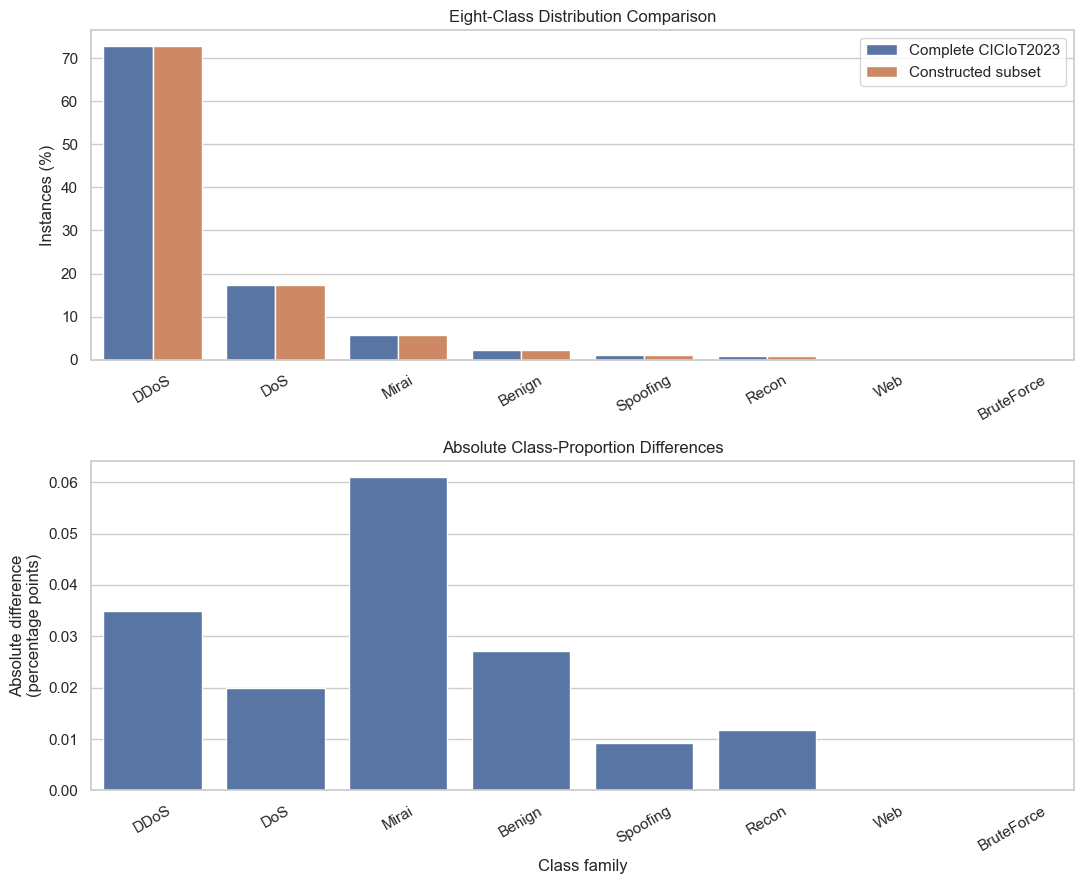

In [81]:
class_plot_data = class_representativeness.melt(
    id_vars="Class",
    value_vars=["Full proportion (%)", "Subset proportion (%)"],
    var_name="Dataset",
    value_name="Proportion (%)",
)
class_plot_data["Dataset"] = class_plot_data["Dataset"].replace(
    {
        "Full proportion (%)": "Complete CICIoT2023",
        "Subset proportion (%)": "Constructed subset",
    }
)

fig, axes = plt.subplots(2, 1, figsize=(11, 9))

sns.barplot(
    data=class_plot_data,
    x="Class",
    y="Proportion (%)",
    hue="Dataset",
    ax=axes[0],
)
axes[0].set_title("Eight-Class Distribution Comparison")
axes[0].set_xlabel("")
axes[0].set_ylabel("Instances (%)")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title="")

sns.barplot(
    data=class_representativeness,
    x="Class",
    y="Absolute difference (percentage points)",
    color="#4C72B0",
    ax=axes[1],
)
axes[1].set_title("Absolute Class-Proportion Differences")
axes[1].set_xlabel("Class family")
axes[1].set_ylabel("Absolute difference\n(percentage points)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
fig.savefig(
    "CICIoT2023_class_distribution_representativeness.pdf",
    bbox_inches="tight",
)
fig.savefig(
    "CICIoT2023_class_distribution_representativeness.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### 6.2 Feature-Distribution Similarity


In [84]:
# Reproducible, memory-bounded feature-reference sampling configuration
FEATURE_RANDOM_SEED = SEED
MARGINAL_REFERENCE_SIZE = 100_000
REFERENCE_PER_CLASS = 20_000
REFERENCE_CHUNK_SIZE = 250_000

raw_feature_columns = [
    column for column in expected_header if column != LABEL_COL
]

if selected_csv_file.resolve() == second_csv_path.resolve():
    raise ValueError(
        "The largest source file and second reference file must be different."
    )

excluded_reference_paths = {
    selected_csv_file.resolve(),
    second_csv_path.resolve(),
}
unused_csv_files = [
    file_path
    for file_path in csv_files
    if file_path.resolve() not in excluded_reference_paths
]

if len(unused_csv_files) != EXPECTED_FILES - 2:
    raise ValueError(
        f"Expected {EXPECTED_FILES - 2} unused source files, but found "
        f"{len(unused_csv_files)}."
    )

print("Independent feature-reference population:")
print(f"Unused source files: {len(unused_csv_files)}")
print(f"Excluded 40% rows from second file: {len(df_second_csv_40):,}")
print(f"Marginal reference-sample cap: {MARGINAL_REFERENCE_SIZE:,}")
print(f"Per-class reference-sample cap: {REFERENCE_PER_CLASS:,}")


Independent feature-reference population:
Unused source files: 167
Excluded 40% rows from second file: 93,154
Marginal reference-sample cap: 100,000
Per-class reference-sample cap: 20,000


In [86]:
def clean_feature_comparison_frame(
    df,
    feature_columns=raw_feature_columns,
    label_col=LABEL_COL,
):
    # Apply identical minimal cleaning before distribution comparison.
    cleaned = df[feature_columns + [label_col]].copy()
    cleaned = group_ciciot2023_classes(cleaned, label_col=label_col)

    cleaned[feature_columns] = cleaned[feature_columns].apply(
        pd.to_numeric,
        errors="coerce",
    )
    cleaned[feature_columns] = cleaned[feature_columns].replace(
        [np.inf, -np.inf],
        np.nan,
    )
    cleaned = cleaned.dropna(
        subset=feature_columns + [label_col]
    ).reset_index(drop=True)

    unknown_classes = set(cleaned[label_col].unique()) - set(CLASS_ORDER)
    if unknown_classes:
        raise ValueError(
            f"Unexpected aggregated classes: {sorted(unknown_classes)}"
        )

    return cleaned


def update_priority_reservoir(current, candidates, size, key_column):
    # Keep the rows with the smallest random priorities.
    if current is None or current.empty:
        combined = candidates
    else:
        combined = pd.concat([current, candidates], ignore_index=True)

    if len(combined) > size:
        combined = combined.nsmallest(size, key_column)

    return combined.reset_index(drop=True)


def update_reference_reservoirs(
    cleaned_chunk,
    marginal_reservoir,
    conditional_reservoirs,
    rng,
):
    # Update marginal and class-conditional random-priority reservoirs.
    marginal_candidates = cleaned_chunk.copy()
    marginal_candidates["_marginal_priority"] = rng.random(
        len(marginal_candidates)
    )
    marginal_reservoir = update_priority_reservoir(
        marginal_reservoir,
        marginal_candidates,
        MARGINAL_REFERENCE_SIZE,
        "_marginal_priority",
    )

    for class_name, class_frame in cleaned_chunk.groupby(
        LABEL_COL,
        sort=False,
    ):
        class_candidates = class_frame.copy()
        class_candidates["_conditional_priority"] = rng.random(
            len(class_candidates)
        )
        conditional_reservoirs[class_name] = update_priority_reservoir(
            conditional_reservoirs.get(class_name),
            class_candidates,
            REFERENCE_PER_CLASS,
            "_conditional_priority",
        )

    return marginal_reservoir, conditional_reservoirs


In [88]:
# Build an independent, non-overlapping reference sample. Random-priority
# sampling yields a reproducible uniform reservoir without loading the full
# reference population into memory.
feature_rng = np.random.default_rng(FEATURE_RANDOM_SEED)
marginal_reference_reservoir = None
conditional_reference_reservoirs = {}
reference_rows_scanned = 0
reference_rows_valid = 0

# First include the excluded 40% partition of the second source file.
reference_frames = [df_second_csv_40]
for reference_frame in reference_frames:
    reference_rows_scanned += len(reference_frame)
    cleaned_reference_frame = clean_feature_comparison_frame(reference_frame)
    reference_rows_valid += len(cleaned_reference_frame)
    (
        marginal_reference_reservoir,
        conditional_reference_reservoirs,
    ) = update_reference_reservoirs(
        cleaned_reference_frame,
        marginal_reference_reservoir,
        conditional_reference_reservoirs,
        feature_rng,
    )

# Then scan all 167 source files that did not contribute to the subset.
for file_number, file_path in enumerate(unused_csv_files, start=1):
    file_rows_scanned = 0
    file_rows_valid = 0

    for chunk in pd.read_csv(
        file_path,
        usecols=raw_feature_columns + [LABEL_COL],
        chunksize=REFERENCE_CHUNK_SIZE,
        low_memory=False,
    ):
        file_rows_scanned += len(chunk)
        cleaned_chunk = clean_feature_comparison_frame(chunk)
        file_rows_valid += len(cleaned_chunk)

        (
            marginal_reference_reservoir,
            conditional_reference_reservoirs,
        ) = update_reference_reservoirs(
            cleaned_chunk,
            marginal_reference_reservoir,
            conditional_reference_reservoirs,
            feature_rng,
        )

    reference_rows_scanned += file_rows_scanned
    reference_rows_valid += file_rows_valid

    print(
        f"[{file_number:03d}/{len(unused_csv_files)}] "
        f"scanned={file_rows_scanned:,}, valid={file_rows_valid:,} - "
        f"{file_path.name}"
    )

marginal_reference_sample = (
    marginal_reference_reservoir
    .drop(columns="_marginal_priority")
    .reset_index(drop=True)
)

conditional_reference_sample = pd.concat(
    [
        class_frame.drop(columns="_conditional_priority")
        for class_frame in conditional_reference_reservoirs.values()
    ],
    ignore_index=True,
)

missing_reference_classes = (
    set(CLASS_ORDER)
    - set(conditional_reference_sample[LABEL_COL].unique())
)
if missing_reference_classes:
    raise ValueError(
        "The reference sample is missing classes: "
        f"{sorted(missing_reference_classes)}"
    )

print("\nIndependent reference sampling completed:")
print(f"Rows scanned: {reference_rows_scanned:,}")
print(f"Valid rows: {reference_rows_valid:,}")
print(f"Marginal reference sample: {len(marginal_reference_sample):,}")
print("Class-conditional reference sample counts:")
display(
    conditional_reference_sample[LABEL_COL]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
    .rename("Reference sample count")
    .to_frame()
)


[001/167] scanned=238,687, valid=238,687 - part-00000-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[002/167] scanned=218,805, valid=218,805 - part-00001-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[003/167] scanned=275,258, valid=275,258 - part-00002-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[004/167] scanned=231,023, valid=231,023 - part-00003-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[005/167] scanned=227,491, valid=227,491 - part-00004-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[006/167] scanned=240,046, valid=240,046 - part-00005-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[007/167] scanned=233,793, valid=233,793 - part-00006-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[008/167] scanned=227,910, valid=227,910 - part-00007-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[009/167] scanned=246,327, valid=246,327 - part-00008-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
[010/167] scanned=227,616, valid=227,616 - part-00009-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv


,Reference sample count
label,
DDoS,20000
DoS,20000
Mirai,20000
Benign,20000
Spoofing,20000
Recon,20000
Web,20000
BruteForce,12898


In [90]:
# Prepare matching subset samples without modifying the main preprocessing
# dataframe used in the following section.
feature_comparison_subset = clean_feature_comparison_frame(
    df_CICIoT2023_concat
)

marginal_subset_sample = feature_comparison_subset.sample(
    n=min(MARGINAL_REFERENCE_SIZE, len(feature_comparison_subset)),
    random_state=FEATURE_RANDOM_SEED,
).reset_index(drop=True)

conditional_subset_parts = []
for class_name in CLASS_ORDER:
    class_frame = feature_comparison_subset.loc[
        feature_comparison_subset[LABEL_COL] == class_name
    ]
    conditional_subset_parts.append(
        class_frame.sample(
            n=min(REFERENCE_PER_CLASS, len(class_frame)),
            random_state=FEATURE_RANDOM_SEED,
        )
    )

conditional_subset_sample = pd.concat(
    conditional_subset_parts,
    ignore_index=True,
)

print(f"Marginal subset sample: {len(marginal_subset_sample):,}")
print("Class-conditional subset sample counts:")
display(
    conditional_subset_sample[LABEL_COL]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
    .rename("Subset sample count")
    .to_frame()
)


Marginal subset sample: 100,000
Class-conditional subset sample counts:


,Subset sample count
label,
DDoS,20000
DoS,20000
Mirai,20000
Benign,13747
Spoofing,6215
Recon,4560
Web,313
BruteForce,166


In [92]:
def benjamini_hochberg(p_values):
    # Return Benjamini-Hochberg-adjusted p-values.
    p_values = np.asarray(p_values, dtype=float)
    number_of_tests = len(p_values)
    order = np.argsort(p_values)
    ranked_p_values = p_values[order]

    adjusted_ranked = (
        ranked_p_values * number_of_tests
        / np.arange(1, number_of_tests + 1)
    )
    adjusted_ranked = np.minimum.accumulate(adjusted_ranked[::-1])[::-1]
    adjusted_ranked = np.clip(adjusted_ranked, 0, 1)

    adjusted = np.empty(number_of_tests, dtype=float)
    adjusted[order] = adjusted_ranked
    return adjusted


def calculate_feature_similarity(subset_values, reference_values):
    # Calculate the SMD and two-sample KS results for one feature.
    subset_values = np.asarray(subset_values, dtype=float)
    reference_values = np.asarray(reference_values, dtype=float)

    subset_mean = float(np.mean(subset_values))
    reference_mean = float(np.mean(reference_values))
    subset_variance = float(np.var(subset_values, ddof=1))
    reference_variance = float(np.var(reference_values, ddof=1))
    pooled_standard_deviation = np.sqrt(
        (subset_variance + reference_variance) / 2
    )

    if pooled_standard_deviation > 0:
        smd = abs(subset_mean - reference_mean) / pooled_standard_deviation
    elif np.isclose(subset_mean, reference_mean):
        smd = 0.0
    else:
        smd = np.inf

    ks_result = ks_2samp(
        subset_values,
        reference_values,
        alternative="two-sided",
        method="auto",
    )

    return {
        "SMD": float(smd),
        "KS statistic": float(ks_result.statistic),
        "KS p-value": float(ks_result.pvalue),
        "Subset sample size": len(subset_values),
        "Reference sample size": len(reference_values),
    }


def smd_category(smd):
    if smd < 0.10:
        return "Negligible"
    if smd < 0.20:
        return "Small"
    if smd < 0.50:
        return "Moderate"
    return "Large"


In [94]:
# Marginal feature comparison
marginal_feature_rows = []
for feature in raw_feature_columns:
    metrics = calculate_feature_similarity(
        marginal_subset_sample[feature].to_numpy(),
        marginal_reference_sample[feature].to_numpy(),
    )
    marginal_feature_rows.append({"Feature": feature, **metrics})

marginal_feature_results = pd.DataFrame(marginal_feature_rows)
marginal_feature_results["KS adjusted p-value"] = benjamini_hochberg(
    marginal_feature_results["KS p-value"].to_numpy()
)
marginal_feature_results["KS significant at FDR 0.05"] = (
    marginal_feature_results["KS adjusted p-value"] < 0.05
)
marginal_feature_results["SMD category"] = (
    marginal_feature_results["SMD"].map(smd_category)
)
marginal_feature_results = marginal_feature_results.sort_values(
    ["SMD", "KS statistic"],
    ascending=False,
    ignore_index=True,
)

# Class-conditional feature comparison
conditional_feature_rows = []
for class_name in CLASS_ORDER:
    subset_class_frame = conditional_subset_sample.loc[
        conditional_subset_sample[LABEL_COL] == class_name
    ]
    reference_class_frame = conditional_reference_sample.loc[
        conditional_reference_sample[LABEL_COL] == class_name
    ]

    for feature in raw_feature_columns:
        metrics = calculate_feature_similarity(
            subset_class_frame[feature].to_numpy(),
            reference_class_frame[feature].to_numpy(),
        )
        conditional_feature_rows.append(
            {"Class": class_name, "Feature": feature, **metrics}
        )

conditional_feature_results = pd.DataFrame(conditional_feature_rows)
conditional_feature_results["KS adjusted p-value"] = benjamini_hochberg(
    conditional_feature_results["KS p-value"].to_numpy()
)
conditional_feature_results["KS significant at FDR 0.05"] = (
    conditional_feature_results["KS adjusted p-value"] < 0.05
)
conditional_feature_results["SMD category"] = (
    conditional_feature_results["SMD"].map(smd_category)
)

conditional_feature_summary = (
    conditional_feature_results
    .groupby("Feature", as_index=False)
    .agg(
        **{
            "Mean class-conditional SMD": ("SMD", "mean"),
            "Maximum class-conditional SMD": ("SMD", "max"),
            "Mean class-conditional KS": ("KS statistic", "mean"),
            "Maximum class-conditional KS": ("KS statistic", "max"),
            "FDR-significant class comparisons": (
                "KS significant at FDR 0.05",
                "sum",
            ),
        }
    )
)

feature_distribution_summary = (
    marginal_feature_results[
        [
            "Feature",
            "SMD",
            "SMD category",
            "KS statistic",
            "KS adjusted p-value",
            "KS significant at FDR 0.05",
        ]
    ]
    .rename(
        columns={
            "SMD": "Marginal SMD",
            "SMD category": "Marginal SMD category",
            "KS statistic": "Marginal KS statistic",
            "KS adjusted p-value": "Marginal KS adjusted p-value",
            "KS significant at FDR 0.05": (
                "Marginal KS significant at FDR 0.05"
            ),
        }
    )
    .merge(conditional_feature_summary, on="Feature", how="left")
    .sort_values(
        ["Maximum class-conditional SMD", "Marginal SMD"],
        ascending=False,
        ignore_index=True,
    )
)

print("Compact feature-distribution summary:")
display(
    feature_distribution_summary.style.format(
        {
            "Marginal SMD": "{:.4f}",
            "Marginal KS statistic": "{:.4f}",
            "Marginal KS adjusted p-value": "{:.4e}",
            "Mean class-conditional SMD": "{:.4f}",
            "Maximum class-conditional SMD": "{:.4f}",
            "Mean class-conditional KS": "{:.4f}",
            "Maximum class-conditional KS": "{:.4f}",
        }
    )
)

marginal_feature_results.to_csv(
    "CICIoT2023_feature_similarity_marginal.csv",
    index=False,
)
conditional_feature_results.to_csv(
    "CICIoT2023_feature_similarity_by_class.csv",
    index=False,
)
feature_distribution_summary.to_csv(
    "CICIoT2023_feature_similarity_summary.csv",
    index=False,
)


Compact feature-distribution summary:


,Feature,Marginal SMD,Marginal SMD category,Marginal KS statistic,Marginal KS adjusted p-value,Marginal KS significant at FDR 0.05,Mean class-conditional SMD,Maximum class-conditional SMD,Mean class-conditional KS,Maximum class-conditional KS,FDR-significant class comparisons
0,urg_count,0.0026,Negligible,0.0019,1.0000e+00,False,0.0407,0.2116,0.0264,0.1039,0
1,rst_count,0.0009,Negligible,0.0023,1.0000e+00,False,0.0389,0.1675,0.0286,0.0994,0
2,HTTP,0.0020,Negligible,0.0004,1.0000e+00,False,0.0278,0.1275,0.0029,0.0081,0
3,Radius,0.0051,Negligible,0.0040,1.0000e+00,False,0.0272,0.1112,0.0266,0.0813,0
4,Std,0.0052,Negligible,0.0040,1.0000e+00,False,0.0271,0.1107,0.0260,0.0821,0
5,syn_count,0.0032,Negligible,0.0026,1.0000e+00,False,0.0292,0.1047,0.0246,0.0782,0
6,Number,0.0030,Negligible,0.0004,1.0000e+00,False,0.0217,0.0982,0.0092,0.0487,0
7,IAT,0.0028,Negligible,0.0035,1.0000e+00,False,0.0219,0.0980,0.0234,0.0786,0
8,Weight,0.0031,Negligible,0.0004,1.0000e+00,False,0.0220,0.0979,0.0092,0.0487,0
9,Max,0.0060,Negligible,0.0044,1.0000e+00,False,0.0222,0.0910,0.0237,0.0789,0


In [96]:
# Compact effect-size and statistical summary for manuscript reporting
number_of_features = len(marginal_feature_results)
number_of_conditional_comparisons = len(conditional_feature_results)

marginal_smd_below_010 = int(
    (marginal_feature_results["SMD"] < 0.10).sum()
)
marginal_smd_below_020 = int(
    (marginal_feature_results["SMD"] < 0.20).sum()
)
conditional_smd_below_010 = int(
    (conditional_feature_results["SMD"] < 0.10).sum()
)
conditional_smd_below_020 = int(
    (conditional_feature_results["SMD"] < 0.20).sum()
)

marginal_ks_significant = int(
    marginal_feature_results["KS significant at FDR 0.05"].sum()
)
conditional_ks_significant = int(
    conditional_feature_results["KS significant at FDR 0.05"].sum()
)

largest_marginal_smd = marginal_feature_results.loc[
    marginal_feature_results["SMD"].idxmax()
]
largest_conditional_smd = conditional_feature_results.loc[
    conditional_feature_results["SMD"].idxmax()
]
largest_marginal_ks = marginal_feature_results.loc[
    marginal_feature_results["KS statistic"].idxmax()
]
largest_conditional_ks = conditional_feature_results.loc[
    conditional_feature_results["KS statistic"].idxmax()
]

compact_results = pd.DataFrame(
    {
        "Result": [
            "Marginal SMD < 0.10",
            "Marginal SMD < 0.20",
            "Largest marginal SMD",
            "FDR-significant marginal KS comparisons",
            "Largest marginal KS statistic",
            "Class-conditional SMD < 0.10",
            "Class-conditional SMD < 0.20",
            "Largest class-conditional SMD",
            "FDR-significant class-conditional KS comparisons",
            "Largest class-conditional KS statistic",
        ],
        "Value": [
            f"{marginal_smd_below_010}/{number_of_features} "
            f"({100 * marginal_smd_below_010 / number_of_features:.2f}%)",
            f"{marginal_smd_below_020}/{number_of_features} "
            f"({100 * marginal_smd_below_020 / number_of_features:.2f}%)",
            f"{largest_marginal_smd['SMD']:.4f} "
            f"({largest_marginal_smd['Feature']})",
            f"{marginal_ks_significant}/{number_of_features}",
            f"{largest_marginal_ks['KS statistic']:.4f} "
            f"({largest_marginal_ks['Feature']})",
            f"{conditional_smd_below_010}/{number_of_conditional_comparisons} "
            f"({100 * conditional_smd_below_010 / number_of_conditional_comparisons:.2f}%)",
            f"{conditional_smd_below_020}/{number_of_conditional_comparisons} "
            f"({100 * conditional_smd_below_020 / number_of_conditional_comparisons:.2f}%)",
            f"{largest_conditional_smd['SMD']:.4f} "
            f"({largest_conditional_smd['Feature']}, "
            f"{largest_conditional_smd['Class']})",
            f"{conditional_ks_significant}/{number_of_conditional_comparisons}",
            f"{largest_conditional_ks['KS statistic']:.4f} "
            f"({largest_conditional_ks['Feature']}, "
            f"{largest_conditional_ks['Class']})",
        ],
    }
)

display(compact_results)

,Result,Value
0,Marginal SMD < 0.10,46/46 (100.00%)
1,Marginal SMD < 0.20,46/46 (100.00%)
2,Largest marginal SMD,0.0113 (TCP)
3,FDR-significant marginal KS comparisons,0/46
4,Largest marginal KS statistic,0.0056 (TCP)
5,Class-conditional SMD < 0.10,362/368 (98.37%)
6,Class-conditional SMD < 0.20,367/368 (99.73%)
7,Largest class-conditional SMD,"0.2116 (urg_count, BruteForce)"
8,FDR-significant class-conditional KS comparisons,0/368
9,Largest class-conditional KS statistic,"0.1039 (urg_count, BruteForce)"


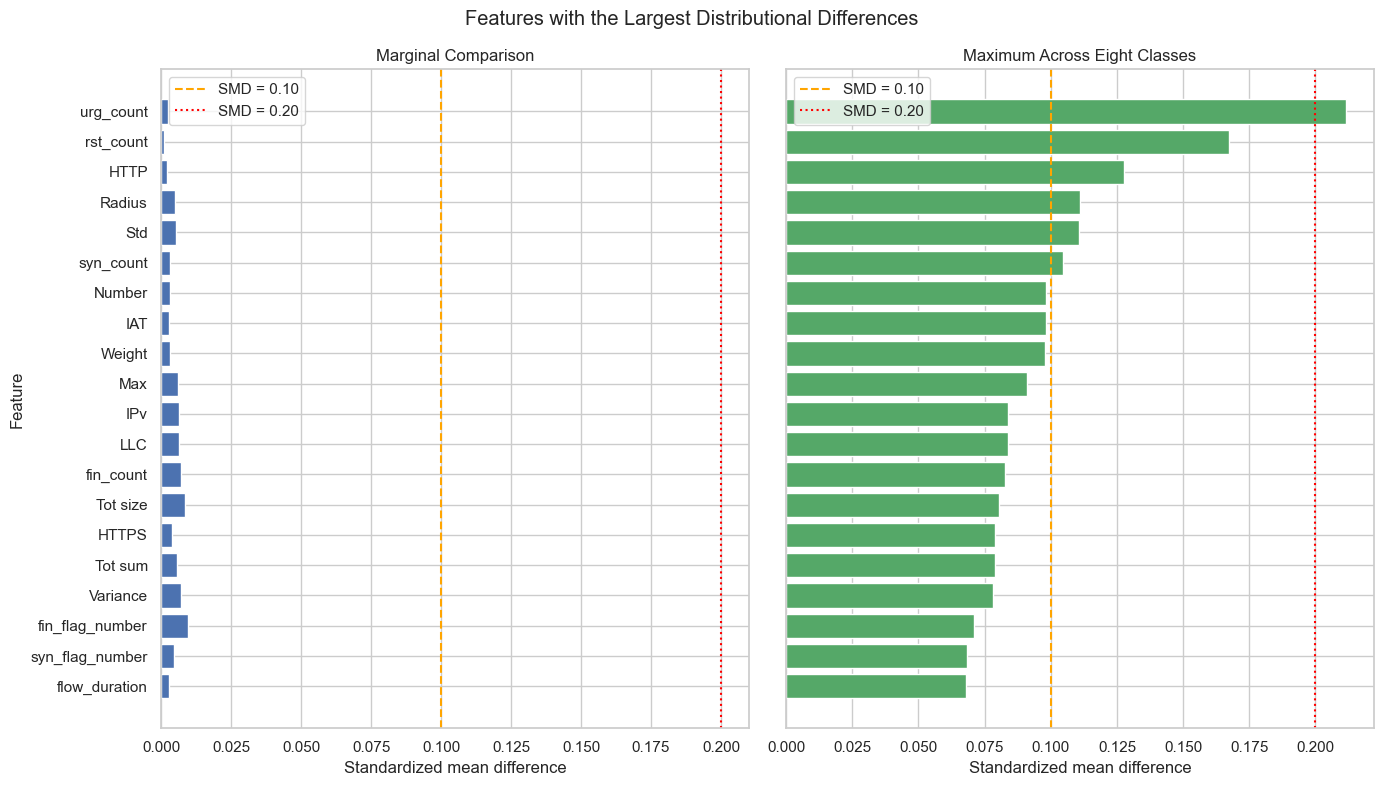

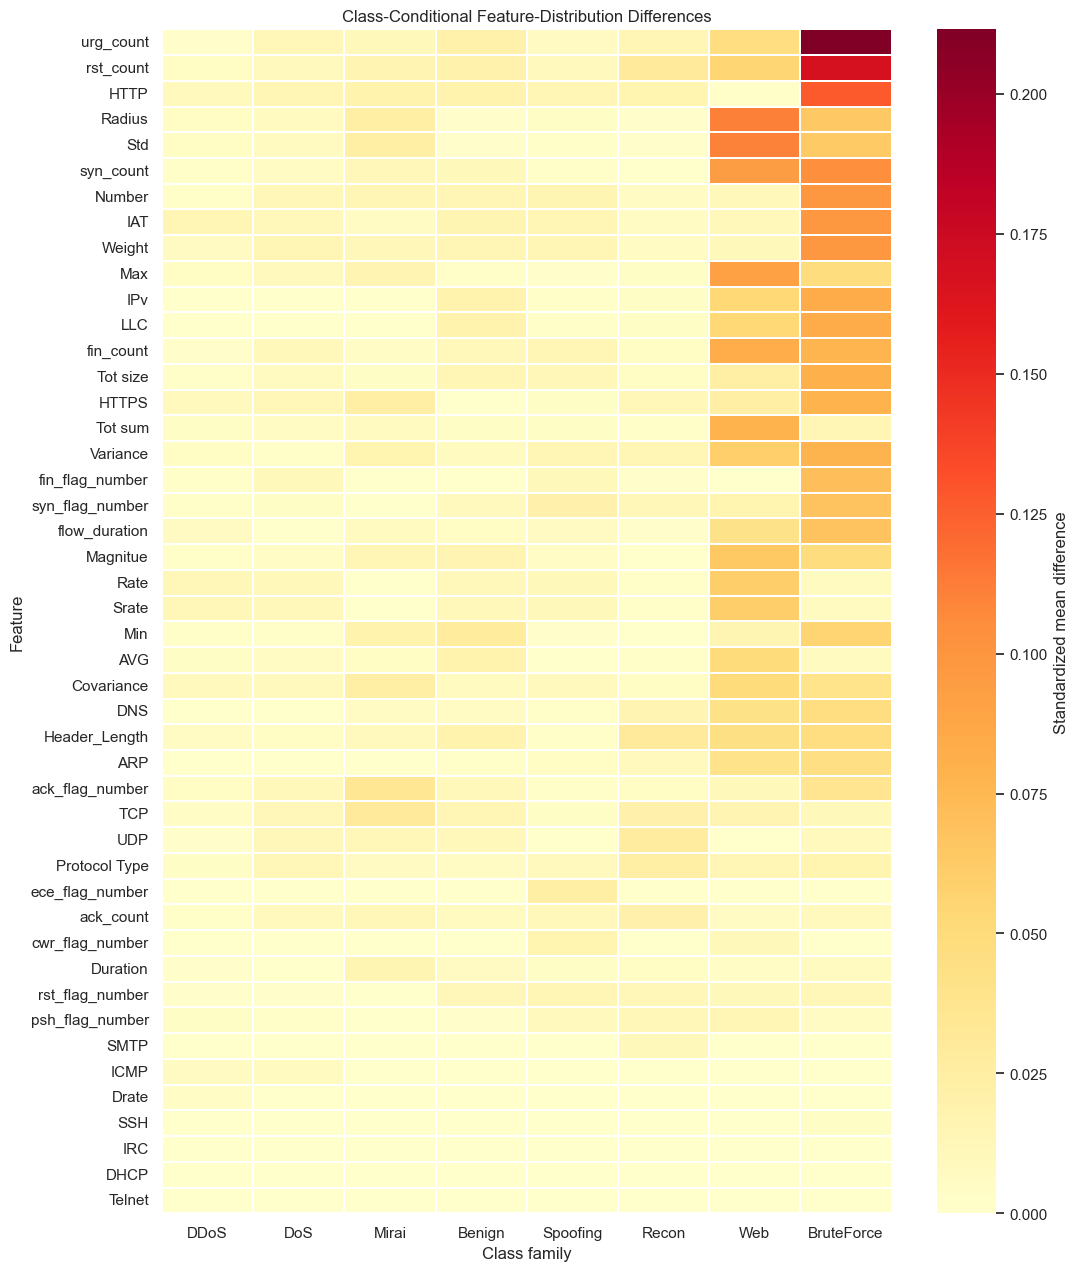

In [98]:
# Figure 1: features with the largest marginal or class-conditional SMD
top_feature_plot = feature_distribution_summary.head(20).copy()
top_feature_plot = top_feature_plot.sort_values(
    "Maximum class-conditional SMD",
    ascending=True,
)

fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)

axes[0].barh(
    top_feature_plot["Feature"],
    top_feature_plot["Marginal SMD"],
    color="#4C72B0",
)
axes[0].axvline(0.10, color="orange", linestyle="--", label="SMD = 0.10")
axes[0].axvline(0.20, color="red", linestyle=":", label="SMD = 0.20")
axes[0].set_title("Marginal Comparison")
axes[0].set_xlabel("Standardized mean difference")
axes[0].set_ylabel("Feature")
axes[0].legend()

axes[1].barh(
    top_feature_plot["Feature"],
    top_feature_plot["Maximum class-conditional SMD"],
    color="#55A868",
)
axes[1].axvline(0.10, color="orange", linestyle="--", label="SMD = 0.10")
axes[1].axvline(0.20, color="red", linestyle=":", label="SMD = 0.20")
axes[1].set_title("Maximum Across Eight Classes")
axes[1].set_xlabel("Standardized mean difference")
axes[1].legend()

fig.suptitle("Features with the Largest Distributional Differences")
plt.tight_layout()
fig.savefig(
    "CICIoT2023_feature_similarity_largest_SMD.pdf",
    bbox_inches="tight",
)
fig.savefig(
    "CICIoT2023_feature_similarity_largest_SMD.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Figure 2: complete class-conditional SMD heatmap
smd_heatmap = (
    conditional_feature_results
    .pivot(index="Feature", columns="Class", values="SMD")
    .reindex(columns=CLASS_ORDER)
)
smd_heatmap = smd_heatmap.loc[
    smd_heatmap.max(axis=1).sort_values(ascending=False).index
]

plt.figure(figsize=(11, max(10, 0.28 * len(smd_heatmap))))
sns.heatmap(
    smd_heatmap,
    cmap="YlOrRd",
    vmin=0,
    linewidths=0.2,
    cbar_kws={"label": "Standardized mean difference"},
)
plt.title("Class-Conditional Feature-Distribution Differences")
plt.xlabel("Class family")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(
    "CICIoT2023_class_conditional_feature_SMD_heatmap.pdf",
    bbox_inches="tight",
)
plt.savefig(
    "CICIoT2023_class_conditional_feature_SMD_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


####  Use previously saved  Eight-Class Subset for the Next Step 


## Next Step: Dataset Cleaning and Anomaly Score Generation

The cleaned eight-class subset can now be used for train/validation/test
partitioning, anomaly-score generation, training-only feature transformations,
class balancing, model training, and evaluation.
